# Merge of Pollutant, Meteo & Traffic data

In [68]:
import pandas as pd
import os
from utils import read_files
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
filenames = ["data/pollutants_h1_17_24.csv", "data/meteodata_h1_17_24.csv", "data/traffic_h1_17_24.csv"]

#df_pollutants = read_files(file_paths=filenames_pollutants, drop_columns=["Status", "Intervall"])

# Creating pandas dataframe instead of using the function read_files
df = pd.concat(
    [pd.read_csv(f) for f in filenames],
    #[pd.read_csv(f).drop(columns=["Status", "Intervall"]) for f in filenames_pollutants],
    ignore_index=True
)

df = pd.DataFrame(df)  # Why does this not give a dataframe with drop-downs as in exercises?
df

,Year,Datetime,Datum_date,Datum_time,Standort,NO,NO2,NOx,O3,PM10,PM2.5,Hr,RainDur,StrGlo,T,WD,WVs,WVv,p,AnzFahrzeuge
0,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Heubeeribüel,6.96,36.78,24.82,1.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,22.68,39.79,38.99,1.14,193.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Schimmelstrasse,38.59,43.14,53.50,1.43,88.93,70.54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Stampfenbachstrasse,9.42,37.71,27.27,1.45,105.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Heubeeribüel,13.54,37.11,30.27,1.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
934875,2024,2024-12-31 19:00:00,2024-12-31,19:00:00,Zch_Heubeeribüel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0
934876,2024,2024-12-31 20:00:00,2024-12-31,20:00:00,Zch_Heubeeribüel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0
934877,2024,2024-12-31 21:00:00,2024-12-31,21:00:00,Zch_Heubeeribüel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0
934878,2024,2024-12-31 22:00:00,2024-12-31,22:00:00,Zch_Heubeeribüel,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.0


In [70]:
import pandas as pd
from functools import reduce

filenames = [
    "data/pollutants_h1_17_24.csv",
    "data/meteodata_h1_17_24.csv",
    "data/traffic_h1_17_24.csv"
]

# Adjust these read options to your files (drop sep/encoding if plain CSV):
read_opts = dict(sep=',', encoding='utf-8', engine='python')

dfs = [pd.read_csv(f, **read_opts) for f in filenames]

dfs[0].head()

,Year,Datetime,Datum_date,Datum_time,Standort,NO,NO2,NOx,O3,PM10,PM2.5
0,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Heubeeribüel,6.96,36.78,24.82,1.82,NaN,NaN
1,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,22.68,39.79,38.99,1.14,193.06,NaN
2,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Schimmelstrasse,38.59,43.14,53.50,1.43,88.93,70.54
3,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Stampfenbachstrasse,9.42,37.71,27.27,1.45,105.88,NaN
4,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Heubeeribüel,13.54,37.11,30.27,1.46,NaN,NaN


In [71]:
dfs[1].head()

,Year,Datetime,Datum_date,Datum_time,Standort,Hr,RainDur,StrGlo,T,WD,WVs,WVv,p
0,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,88.22,0.0,NaN,-1.73,194.17,0.36,0.32,977.84
1,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Schimmelstrasse,84.78,0.0,NaN,-1.33,337.53,NaN,0.99,980.34
2,2017,2017-01-01 00:00:00+01:00,2017-01-01,00:00:00,Zch_Stampfenbachstrasse,87.41,0.0,0.03,-1.65,292.05,1.36,1.36,977.22
3,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Rosengartenstrasse,88.35,0.0,NaN,-2.06,145.18,0.22,0.22,977.24
4,2017,2017-01-01 01:00:00+01:00,2017-01-01,01:00:00,Zch_Schimmelstrasse,83.94,0.0,NaN,-1.61,341.51,NaN,0.85,979.76


In [72]:
dfs[2].head()

,Year,Datetime,Datum_date,Datum_time,Standort,AnzFahrzeuge
0,2017,2017-01-01 00:00:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,611.0
1,2017,2017-01-01 01:00:00,2017-01-01,01:00:00,Zch_Rosengartenstrasse,1278.0
2,2017,2017-01-01 02:00:00,2017-01-01,02:00:00,Zch_Rosengartenstrasse,950.0
3,2017,2017-01-01 03:00:00,2017-01-01,03:00:00,Zch_Rosengartenstrasse,716.0
4,2017,2017-01-01 04:00:00,2017-01-01,04:00:00,Zch_Rosengartenstrasse,638.0


Unify the Date column to not have a mix of time aware (time zone) and not dfs

In [80]:
import pandas as pd

TZ = "Europe/Zurich"

def to_local_naive(series):
    """
    Parse any strings; if tz-aware, convert to Europe/Zurich and drop tz.
    If tz-naive, assume it's already local time and leave as naive.
    """
    s = pd.to_datetime(series, errors="coerce")
    if pd.api.types.is_datetime64tz_dtype(s):
        # unify to local time, then drop tz
        s = s.dt.tz_convert(TZ).dt.tz_localize(None)
    return s

def build_datetime(df):
    # Use existing 'Datetime' if present; otherwise build from date + time columns
    if "Datetime" in df.columns:
        raw = df["Datetime"]
    elif {"Datum_date", "Datum_time"} <= set(df.columns):
        raw = df["Datum_date"].astype(str) + " " + df["Datum_time"].astype(str)
    else:
        raise ValueError("Need 'Datetime' or ('Datum_date' + 'Datum_time') to build a timestamp.")
    df["Datetime"] = to_local_naive(raw)
    return df

# Apply to each source BEFORE merging
for d in dfs:  # dfs = [df_pollutants, df_meteo, df_traffic]
    build_datetime(d)
    d["Standort"] = d["Standort"].astype(str).str.strip()

# ... now run your prep/merge (groupby on keys to dedupe first!), then:
merged["Standort"] = merged["Standort"].astype(str)        # avoid categorical sort issues
merged["Datetime"] = pd.to_datetime(merged["Datetime"], utc=True)    # ensure dtype is datetime64[ns] (naive)
merged = merged.sort_values(["Standort", "Datetime"]).reset_index(drop=True)

print(merged["Datetime"].dtype)


C:\Users\thimo\AppData\Local\Temp\ipykernel_57652\2978785414.py:11: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(s):
C:\Users\thimo\AppData\Local\Temp\ipykernel_57652\2978785414.py:11: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(s):
C:\Users\thimo\AppData\Local\Temp\ipykernel_57652\2978785414.py:11: DeprecationWarning: is_datetime64tz_dtype is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.DatetimeTZDtype)` instead.
  if pd.api.types.is_datetime64tz_dtype(s):


datetime64[ns, UTC]


In [81]:
import pandas as pd

# Unpack your three DataFrames
df_pollutants, df_meteo, df_traffic = dfs  # adjust if you hold them differently
KEYS = ["Datetime", "Standort"]

def prep(df, value_cols, tag):
    """Keep only keys + needed value columns, normalize keys, collapse duplicates, tag columns."""
    df = df.copy()

    # Build/normalize Datetime
    if "Datetime" in df.columns:
        df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
    elif {"Datum_date", "Datum_time"} <= set(df.columns):
        df["Datetime"] = pd.to_datetime(df["Datum_date"] + " " + df["Datum_time"], errors="coerce")
    else:
        raise ValueError("No datetime available. Provide 'Datetime' or ('Datum_date' + 'Datum_time').")

    # Clean station
    df["Standort"] = df["Standort"].astype(str).str.strip()

    # Keep only the columns we need (prevents suffix collisions)
    keep = KEYS + [c for c in value_cols if c in df.columns]
    df = df[keep]

    # Ensure one row per key (choose aggregation rule that fits your data)
    # 'first' avoids cartesian explosions during merge
    df = df.groupby(KEYS, as_index=False).first()

    # Rename value columns with a source tag to avoid .x/.y suffixes
    df = df.rename(columns={c: f"{c}_{tag}" for c in df.columns if c not in KEYS})

    return df

# Choose the columns you actually want from each source
poll_cols  = ["NO", "NO2", "NOx", "O3", "PM10", "PM2.5"]
meteo_cols = ["Hr", "RainDur", "StrGlo", "T", "WD", "WVs", "WVv", "p"]
traf_cols  = ["AnzFahrzeuge"]

P = prep(df_pollutants, poll_cols,  "poll")
M = prep(df_meteo,      meteo_cols, "meteo")
T = prep(df_traffic,    traf_cols, "traffic")

# Optional: reduce memory footprint of numerics
for d in (P, M, T):
    num_cols = d.select_dtypes(include="number").columns
    d[num_cols] = d[num_cols].astype("float32")

# Merge by index join (often lighter than repeated column alignment)
merged = (
    P.set_index(KEYS)
     .join(M.set_index(KEYS), how="outer")
     .join(T.set_index(KEYS), how="outer")
     .reset_index()
    # If you still prefer merge:
    # P.merge(M, on=KEYS, how="outer", validate="one_to_one")\
    #  .merge(T, on=KEYS, how="outer", validate="one_to_one")
)

# Sort for readability
merged = merged.sort_values(KEYS).reset_index(drop=True)
print(merged.shape)
merged.head()

(275499, 17)


,Datetime,Standort,NO_poll,NO2_poll,NOx_poll,O3_poll,PM10_poll,PM2.5_poll,Hr_meteo,RainDur_meteo,StrGlo_meteo,T_meteo,WD_meteo,WVs_meteo,WVv_meteo,p_meteo,AnzFahrzeuge_traffic
0,2017-01-01 00:00:00,Zch_Heubeeribüel,6.96,36.779999,24.820000,1.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017-01-01 00:00:00,Zch_Rosengartenstrasse,22.68,39.790001,38.990002,1.14,193.059998,NaN,88.220001,0.0,NaN,-1.73,194.169998,0.36,0.32,977.840027,611.0
2,2017-01-01 00:00:00,Zch_Schimmelstrasse,38.59,43.139999,53.500000,1.43,88.930000,70.540001,84.779999,0.0,NaN,-1.33,337.529999,NaN,0.99,980.340027,344.0
3,2017-01-01 00:00:00,Zch_Stampfenbachstrasse,9.42,37.709999,27.270000,1.45,105.879997,NaN,87.410004,0.0,0.03,-1.65,292.049988,1.36,1.36,977.219971,NaN
4,2017-01-01 01:00:00,Zch_Heubeeribüel,13.54,37.110001,30.270000,1.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [82]:
del df_merged
# Example: drop trailing _poll/_meteo/_traffic (keep the base name)
def strip_suffixes(df, suffixes=("_poll", "_meteo", "_traffic", "_x", "_y", "_z")):
    new_cols = []
    for c in df.columns:
        for s in suffixes:
            if c.endswith(s):
                c = c[: -len(s)]
                break
        new_cols.append(c)
    df.columns = new_cols
    return df

df_merged = strip_suffixes(merged)
df_merged.head()

,Datetime,Standort,NO,NO2,NOx,O3,PM10,PM2.5,Hr,RainDur,StrGlo,T,WD,WVs,WVv,p,AnzFahrzeuge
0,2017-01-01 00:00:00,Zch_Heubeeribüel,6.96,36.779999,24.820000,1.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017-01-01 00:00:00,Zch_Rosengartenstrasse,22.68,39.790001,38.990002,1.14,193.059998,NaN,88.220001,0.0,NaN,-1.73,194.169998,0.36,0.32,977.840027,611.0
2,2017-01-01 00:00:00,Zch_Schimmelstrasse,38.59,43.139999,53.500000,1.43,88.930000,70.540001,84.779999,0.0,NaN,-1.33,337.529999,NaN,0.99,980.340027,344.0
3,2017-01-01 00:00:00,Zch_Stampfenbachstrasse,9.42,37.709999,27.270000,1.45,105.879997,NaN,87.410004,0.0,0.03,-1.65,292.049988,1.36,1.36,977.219971,NaN
4,2017-01-01 01:00:00,Zch_Heubeeribüel,13.54,37.110001,30.270000,1.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [83]:
#df_pollutants["Date"] = pd.to_datetime(df_pollutants["Datum"], errors="coerce")

# 2) Create date and time columns
df_merged["Year"] = df_merged["Datetime"].dt.year
df_merged["Month"] = df_merged["Datetime"].dt.month
df_merged["Date"] = df_merged["Datetime"].dt.date      # dtype: object (date objects)
df_merged["Time"] = df_merged["Datetime"].dt.time      # dtype: object (time objects)    

Sort columns of df

In [88]:
cols_oder = ["Year", "Month", "Date", "Time", "Datetime", "Standort"] + [c for c in df_merged.columns if c not in ["Year", "Month", "Date", "Time", "Datetime", "Standort"]]
df_merged = df_merged[cols_oder]
df_merged.head()

,Year,Month,Date,Time,Datetime,Standort,NO,NO2,NOx,O3,...,PM2.5,Hr,RainDur,StrGlo,T,WD,WVs,WVv,p,AnzFahrzeuge
0,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Heubeeribüel,6.96,36.779999,24.820000,1.82,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Rosengartenstrasse,22.68,39.790001,38.990002,1.14,...,NaN,88.220001,0.0,NaN,-1.73,194.169998,0.36,0.32,977.840027,611.0
2,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Schimmelstrasse,38.59,43.139999,53.500000,1.43,...,70.540001,84.779999,0.0,NaN,-1.33,337.529999,NaN,0.99,980.340027,344.0
3,2017,1,2017-01-01,00:00:00,2017-01-01 00:00:00,Zch_Stampfenbachstrasse,9.42,37.709999,27.270000,1.45,...,NaN,87.410004,0.0,0.03,-1.65,292.049988,1.36,1.36,977.219971,NaN
4,2017,1,2017-01-01,01:00:00,2017-01-01 01:00:00,Zch_Heubeeribüel,13.54,37.110001,30.270000,1.46,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [89]:
# Display df_pollutants info and missing values
print("df_merged shape:", df_merged.shape)
print("\nMissing values per column:")
print(df_merged.isnull().sum())
print("\nData types:")
print(df_merged.dtypes)

df_merged shape: (275499, 21)

Missing values per column:
Year                 0
Month                0
Date                 0
Time                 0
Datetime             0
Standort             0
NO              177029
NO2             177048
NOx             177048
O3              176205
PM10            198034
PM2.5           202664
Hr               26678
RainDur          41345
StrGlo          196765
T                24613
WD               42973
WVs              79993
WVv              42973
p                24325
AnzFahrzeuge     62245
dtype: int64

Data types:
Year                     int32
Month                    int32
Date                    object
Time                    object
Datetime        datetime64[ns]
Standort                object
NO                     float32
NO2                    float32
NOx                    float32
O3                     float32
PM10                   float32
PM2.5                  float32
Hr                     float32
RainDur                float32

In [93]:
# --- Identify key and parameter columns ---
key_cols = [c for c in ["Standort", "Date", "Time"] if c in df_merged.columns]
pollutant_cols = [c for c in df_merged.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Date" not in key_cols:
    raise KeyError("Column 'Date' is required (date-only).")

# Ensure date-only type for coverage stats
df_merged["Date"] = pd.to_datetime(df_merged["Date"], errors="coerce").dt.date
# --- Station-level base coverage: rows & date span ---
base = (df_merged
        .groupby("Standort", as_index=True)
        .agg(n_rows=("Standort", "size"),
             n_days=("Date", "nunique"),
             min_date=("Date", "min"),
             max_date=("Date", "max")))

# --- Missing counts per pollutant (per station) ---
miss_by_station = (df_merged[pollutant_cols]
                   .isna()
                   .groupby(df_merged["Standort"])
                   .sum())

# --- Missing rates per pollutant (divide by the station's row count) ---
#miss_rate_by_station = miss_by_station.div(base["n_rows"], axis=0)

# --- Combined wide summary (counts + rates, alongside coverage) ---
summary_wide = (base
                .join(miss_by_station.add_prefix("miss_"))
                #.join(miss_rate_by_station.add_prefix("rate_"))
               )

print("\nStation-level summary (counts):")# & rates):")
print(summary_wide)  # Each station: n_rows, n_days, min/max date, miss_* and rate_* per pollutant



Station-level summary (counts):
                         n_rows  n_days    min_date    max_date  miss_Year  \
Standort                                                                     
Zch_Heubeeribüel          38982    1631  2017-01-01  2025-12-30          0   
Zch_Rosengartenstrasse    78839    3286  2017-01-01  2025-12-30          0   
Zch_Schimmelstrasse       78839    3286  2017-01-01  2025-12-30          0   
Zch_Stampfenbachstrasse   78839    3286  2017-01-01  2025-12-30          0   

                         miss_Month  miss_Datetime  miss_NO  miss_NO2  \
Standort                                                                
Zch_Heubeeribüel                  0              0    14588     14607   
Zch_Rosengartenstrasse            0              0    54491     54491   
Zch_Schimmelstrasse               0              0    54174     54174   
Zch_Stampfenbachstrasse           0              0    53776     53776   

                         miss_NOx  ...  miss_PM2.5  miss_Hr

In [95]:
# --- Identify key and pollutant columns ---
key_cols = [c for c in ["Standort", "Date", "Time"] if c in df_merged.columns]
parameters_cols = [c for c in df_merged.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Date" not in key_cols:
    raise KeyError("Column 'Date' is required (date-only key).")

# --- Ensure date type and derive year ---
# (Works whether Date is a string, datetime.date, or Timestamp.)
df_merged = df_merged.copy()
df_merged["Date"] = pd.to_datetime(df_merged["Date"], errors="coerce")
#df_merged["Year"] = df_merged["Date"].dt.year

# Drop rows where year couldn't be parsed (optional)
dfp = df_merged.dropna(subset=["Year"]).copy()

# --- Base coverage per (Station, Year) ---
base_year = (dfp
    .groupby(["Standort", "Year"], as_index=True)
    .agg(
        n_rows=("Standort", "size"),              # total rows (daily or hourly)
        n_days=("Date", "nunique"),         # number of distinct days
        min_date=("Date", "min"),
        max_date=("Date", "max"),
    )
)

# --- Missing counts per pollutant per (Station, Year) ---
miss_by_station_year = (dfp[parameters_cols]
    .isna()
    .groupby([dfp["Standort"], dfp["Year"]])     # use Series as grouper
    .sum()
)

# --- Missing rates (divide by n_rows per (Station, Year)) ---
#miss_rate_by_station_year = miss_by_station_year.div(base_year["n_rows"], axis=0)

# --- Wide summary: coverage + missing counts + missing rates ---
summary_wide_year = (base_year
    .join(miss_by_station_year.add_prefix("miss_"))
   # .join(miss_rate_by_station_year.add_prefix("rate_"))
)

print("\nStation-level summary per year (wide):")
print(summary_wide_year.head(20))  # MultiIndex rows: (Standort, Year)

# UNCOMMENT TO GET RELATIVE MISSING RATES AS TIDY DATAFRAME

# --- Tidy summary: one row per (Station, Year, Pollutant) with counts & rates ---
#miss_tidy_year = (miss_by_station_year
#    .reset_index()
#    .melt(id_vars=["Standort", "Year"], var_name="Parameter", value_name="missing_count")
#)

#miss_tidy_year = miss_tidy_year.merge(
#    base_year["n_rows"].rename("n_rows").reset_index(),
#    on=["Standort", "Year"],
#    how="left"
#)
#miss_tidy_year["missing_rate"] = miss_tidy_year["missing_count"] / miss_tidy_year["n_rows"]
#miss_tidy_year = miss_tidy_year.sort_values(["Standort", "Year", "Parameter"]).reset_index(drop=True)
#print("\nTidy station-year-pollutant NA summary:")
#print(miss_tidy_year.head(20))


Station-level summary per year (wide):
                             n_rows  n_days   min_date   max_date  miss_Year  \
Standort               Year                                                    
Zch_Heubeeribüel       2017    3552     149 2017-01-01 2017-12-31          0   
                       2018    3552     149 2018-01-01 2018-12-31          0   
                       2019    3720     156 2019-01-01 2019-12-31          0   
                       2021    3552     149 2021-01-01 2021-12-31          0   
                       2022    3552     149 2022-01-01 2022-12-31          0   
                       2023    3552     149 2023-01-01 2023-12-31          0   
                       2024    8783     366 2024-01-01 2024-12-31          0   
                       2025    8719     364 2025-01-01 2025-12-30          0   
Zch_Rosengartenstrasse 2017    8759     365 2017-01-01 2017-12-31          0   
                       2018    8759     365 2018-01-01 2018-12-31          0   


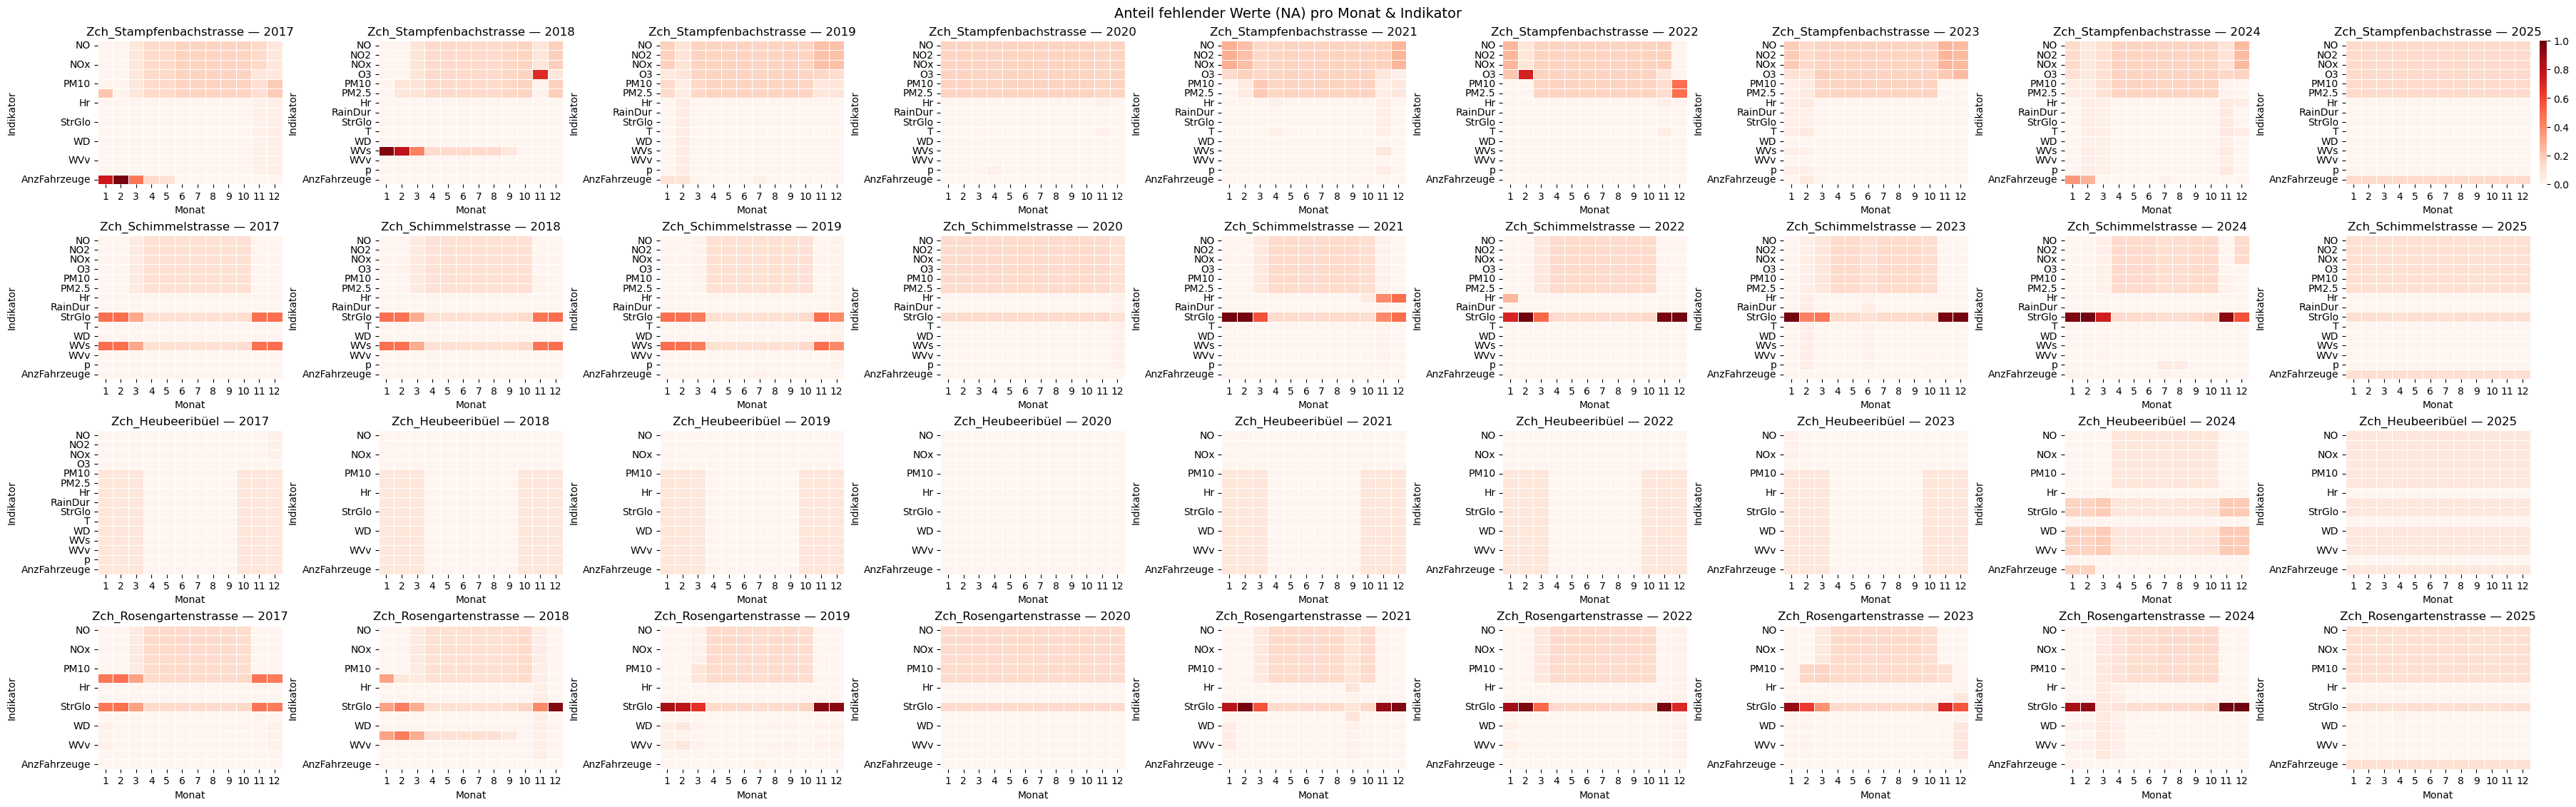

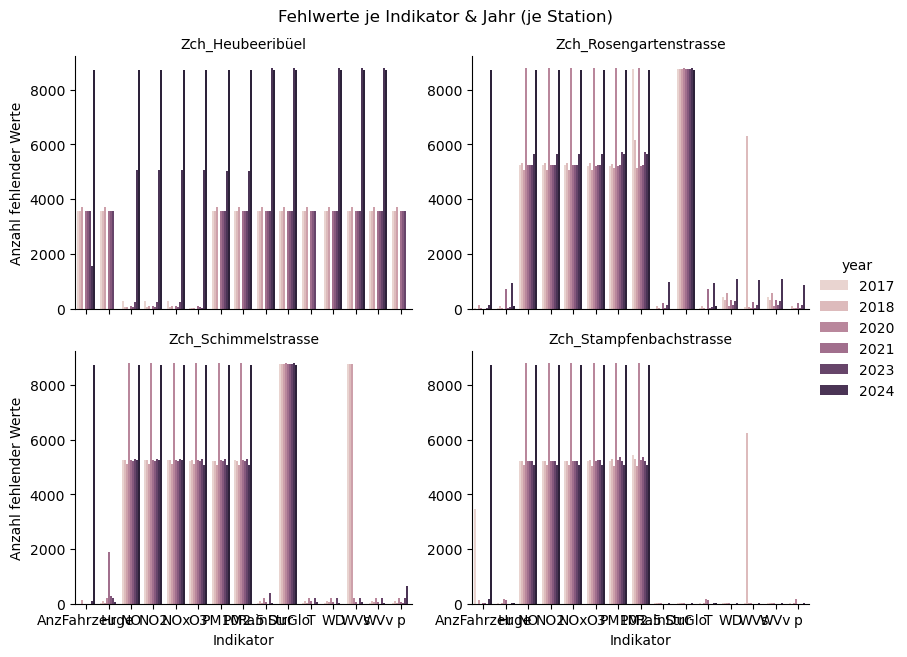

In [97]:
# =========================
# 1) Build a tidy 'missing' table
# =========================
key_cols = [c for c in ["Year", "Month", "Date", "Time", "Datetime", "Standort"] if c in df_merged.columns]
parameters_cols = [c for c in df_merged.columns if c not in key_cols]
# Melt to long format: one row per (keys, Parameter), with value column 'Wert'
long_vals = df_merged.melt(
    id_vars=key_cols,
    value_vars=parameters_cols,
    var_name="Parameter",
    value_name="Wert"
)

# Keep only rows where the pollutant value is missing
na_long = long_vals[long_vals["Wert"].isna()].drop(columns="Wert").reset_index(drop=True)
na_long

# Choose your parameters & stations
PARAMS = parameters_cols #["NO", "NO2", "NOx", "O3", "PM10", "PM2.5"]  # adjust to taste
stations_all = na_long["Standort"].unique().tolist()
STATIONS5 = stations_all[:4]  # or explicitly pick the four you want

# Prepare year/month
na_long["date_ts"] = pd.to_datetime(na_long["Date"], errors="coerce")
na_long["year"] = na_long["date_ts"].dt.year
na_long["month"] = na_long["date_ts"].dt.month

# Filter to desired subset
miss_sub = na_long[na_long["Standort"].isin(STATIONS5) & na_long["Parameter"].isin(PARAMS)].copy()

# 1) Monthly heatmap: missing rate per (station, year, month, parameter)
# We need denominators (how many expected rows per month) — in a daily matrix it’s one per day, in hourly 24/day.
# Using `mean` of boolean is fine if your pivot has one row per day; if hourly, it is fraction of hours missing in that month.

monthly_rate = (
    miss_sub.groupby(["Standort", "year", "month", "Parameter"], dropna=True)
            .size()                              # count of missing entries
            .reset_index(name="missing_count")
)

# To get rates, we need total expected entries per (station, year, month, parameter).
# If the pivot is daily with one row per day per station, total days per month:
days_per_month = (
    na_long.groupby(["Standort", "year", "month"])
           .size()
           .reset_index(name="total_rows_month")  # total rows across all params; we'll assume same for each param
)

monthly_rate = monthly_rate.merge(days_per_month, on=["Standort", "year", "month"], how="left")
monthly_rate["missing_rate"] = monthly_rate["missing_count"] / monthly_rate["total_rows_month"]

# Fill in missing combinations to show zeros in the heatmap
full_index = pd.MultiIndex.from_product(
    [STATIONS5, sorted(miss_sub["year"].dropna().unique()), range(1,13), PARAMS],
    names=["Standort", "year", "month", "Parameter"]
).to_frame(index=False)

monthly_rate = full_index.merge(monthly_rate,
                                on=["Standort", "year", "month", "Parameter"],
                                how="left").fillna({"missing_rate": 0.0})

# Plot grid: rows = stations, cols = years
years_sorted = sorted(monthly_rate["year"].unique())
nrows, ncols = len(STATIONS5), len(years_sorted)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,
                         figsize=(4*ncols, 2.8*nrows), constrained_layout=True)

# Ensure axes is 2D
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1:
    axes = axes.reshape(1, -1)

for i, st in enumerate(STATIONS5):
    for j, yr in enumerate(years_sorted):
        ax = axes[i, j]
        mat = (
            monthly_rate[(monthly_rate["Standort"] == st) & (monthly_rate["year"] == yr)]
            .pivot(index="Parameter", columns="month", values="missing_rate")
            .reindex(index=PARAMS)
        )
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap="Reds",
                    cbar=(i==0 and j==ncols-1), linewidths=0.5, linecolor="white")
        ax.set_title(f"{st} — {yr}")
        ax.set_xlabel("Monat")
        ax.set_ylabel("Indikator")
        ax.set_xticklabels([str(m) for m in range(1, 13)], rotation=0)

fig.suptitle("Anteil fehlender Werte (NA) pro Monat & Indikator", fontsize=14)
plt.show()

# 2) Grouped bar chart: counts per pollutant per station, hue = year
counts = (
    miss_sub.groupby(["Standort", "Parameter", "year"], dropna=True)
            .size()
            .reset_index(name="missing_count")
)

g = sns.catplot(
    data=counts, x="Parameter", y="missing_count", hue="year", col="Standort",
    kind="bar", col_wrap=2, sharey=False, height=3.2, aspect=1.3
)
g.set_titles("{col_name}")
g.set_axis_labels("Indikator", "Anzahl fehlender Werte")
plt.suptitle("Fehlwerte je Indikator & Jahr (je Station)", y=1.02)
plt.show()

In [98]:
# check time during summer time
df_merged.loc[df_merged['Date'].dt.date == pd.to_datetime('2024-06-18').date(), 'Date']

221711   2024-06-18
221712   2024-06-18
221713   2024-06-18
221714   2024-06-18
221715   2024-06-18
            ...    
221802   2024-06-18
221803   2024-06-18
221804   2024-06-18
221805   2024-06-18
221806   2024-06-18
Name: Date, Length: 96, dtype: datetime64[ns]

In [99]:
df_merged.to_csv("data/merged_h1_17_24.csv", index=False)